In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [13]:
closing_index = pd.read_csv('TRD_Index.csv', header=0, skiprows=[1, 2], dtype={'Indexcd': str})
_300index = closing_index[closing_index['Indexcd'] == '000300'].reset_index(drop=True)
_300index['Trddt'] = pd.to_datetime(_300index['Trddt'])
_300index

,Indexcd,Trddt,Clsindex
0,000300,2006-01-04,941.428
1,000300,2006-01-05,959.134
2,000300,2006-01-06,970.032
3,000300,2006-01-09,975.253
4,000300,2006-01-10,978.154
...,...,...,...
4369,000300,2023-12-25,3347.451
4370,000300,2023-12-26,3324.790
4371,000300,2023-12-27,3336.357
4372,000300,2023-12-28,3414.540


In [14]:
_300index['month'] = _300index['Trddt'].dt.to_period('M')
monthly_data = _300index.groupby('month').last().reset_index()
monthly_data['monthly_return'] = monthly_data['Clsindex'].astype(float).pct_change()
monthly_returns = monthly_data.dropna()
monthly_returns
    

,month,Indexcd,Trddt,Clsindex,monthly_return
1,2006-02,000300,2006-02-28,1053.010,0.043000
2,2006-03,000300,2006-03-31,1061.088,0.007671
3,2006-04,000300,2006-04-28,1172.347,0.104854
4,2006-05,000300,2006-05-31,1365.451,0.164716
5,2006-06,000300,2006-06-30,1393.963,0.020881
...,...,...,...,...,...
211,2023-08,000300,2023-08-31,3765.268,-0.062113
212,2023-09,000300,2023-09-28,3689.517,-0.020118
213,2023-10,000300,2023-10-31,3572.506,-0.031714
214,2023-11,000300,2023-11-30,3496.203,-0.021358


In [15]:
mean = monthly_returns['monthly_return'].mean()
std = monthly_returns['monthly_return'].std()
skewness = monthly_returns['monthly_return'].skew()
kurtosis = monthly_returns['monthly_return'].kurt()
print(f"Mean: {mean*100:.2f}%")
print(f"Standard Deviation: {std*100:.2f}%")
print(f"Skewness: {skewness:.4f}")
print(f"Kurtosis: {kurtosis:.4f}")


Mean: 0.90%
Standard Deviation: 8.17%
Skewness: 0.0184
Kurtosis: 1.4551


C:\Users\sirui\AppData\Local\Temp\ipykernel_31140\2968507474.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


[]

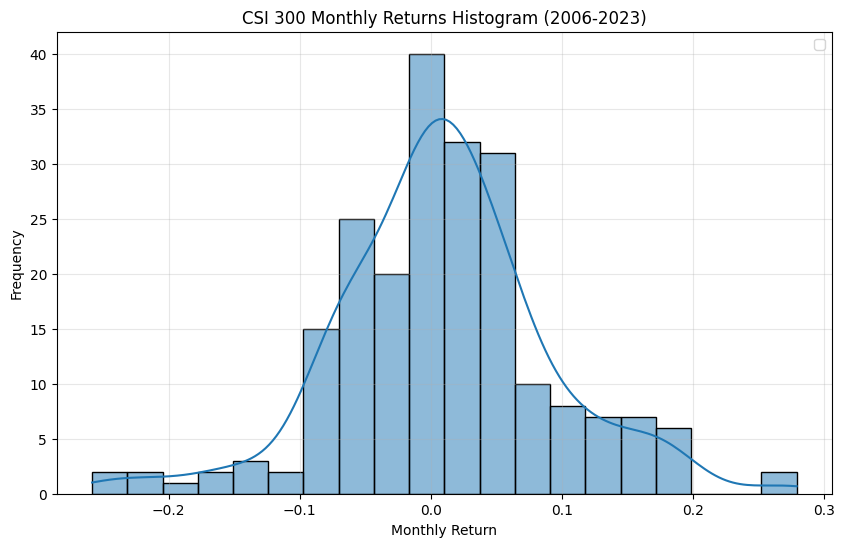

In [16]:
plt.figure(figsize=(10, 6))
sns.histplot(monthly_returns['monthly_return'], kde=True, bins=20)
plt.title('CSI 300 Monthly Returns Histogram (2006-2023)')
plt.xlabel('Monthly Return')
plt.ylabel('Frequency')
# plt.axvline(x=mean, color='r', linestyle='--', label=f'Mean: {mean*100:.2f}%')
plt.legend()
plt.grid(True, alpha=0.3)
plt.plot()

In [17]:
from scipy import stats
shapiro_test = stats.shapiro(monthly_returns['monthly_return'])
jb_test = stats.jarque_bera(monthly_returns['monthly_return'])
if shapiro_test[1] < 0.05 or jb_test[1] < 0.05:
        print("Conclusion: Based on the statistical tests, there is evidence to reject the null hypothesis")
        print("that the CSI 300 monthly returns follow a normal distribution.")
else:
        print("Conclusion: Based on the statistical tests, there is no strong evidence to reject")
        print("the hypothesis that CSI 300 monthly returns follow a normal distribution.")



Conclusion: Based on the statistical tests, there is evidence to reject the null hypothesis
that the CSI 300 monthly returns follow a normal distribution.


### Problem 2

###

In [2]:
weekly_returns = pd.read_csv('TRD_Week.csv', header=0, skiprows=[1, 2], dtype={'Stkcd': str})
weekly_returns1 = pd.read_csv('TRD_Week1.csv', header=0, skiprows=[1, 2], dtype={'Stkcd': str})
weekly_returns = pd.concat([weekly_returns, weekly_returns1], ignore_index=True)
weekly_returns = weekly_returns[weekly_returns['Trdwnt'] < '2023-01'].reset_index(drop=True)
weekly_returns

,Stkcd,Trdwnt,Wretnd
0,000001,2017-03,0.006550
1,000001,2017-04,0.011931
2,000001,2017-05,-0.007503
3,000001,2017-06,0.007559
4,000001,2017-07,0.006431
...,...,...,...
1192892,873527,2022-49,-0.005513
1192893,873527,2022-50,-0.024390
1192894,873527,2022-51,-0.019318
1192895,873527,2022-52,-0.067207


In [13]:
df= pd.read_excel('weekly_risk_free_rate(1).xlsx', sheet_name='Sheet1')
df['trading_date_yw'] = pd.to_datetime(df['trading_date_yw'])
df.set_index('trading_date_yw', inplace=True)
df['Trdwnt'] = df.index.to_period('W').strftime('%Y-%U')
df

,risk_free_return,Trdwnt
trading_date_yw,,
2017-01-01,0.000571,2017-01
2017-01-08,0.000738,2017-02
2017-01-15,0.000543,2017-03
2017-01-22,0.000774,2017-04
2017-01-29,0.000802,2017-05
...,...,...
2022-11-26,0.000444,2022-48
2022-12-03,0.000471,2022-49
2022-12-10,0.000477,2022-50


In [17]:
final_df= pd.merge(weekly_returns,df, on = 'Trdwnt', how = 'left')
final_df

,Stkcd,Trdwnt,Wretnd,risk_free_return
0,000001,2017-03,0.006550,0.000543
1,000001,2017-04,0.011931,0.000774
2,000001,2017-05,-0.007503,0.000802
3,000001,2017-06,0.007559,0.000817
4,000001,2017-07,0.006431,0.000575
...,...,...,...,...
1192892,873527,2022-49,-0.005513,0.000471
1192893,873527,2022-50,-0.024390,0.000477
1192894,873527,2022-51,-0.019318,0.000459
1192895,873527,2022-52,-0.067207,0.000432


In [18]:
market_returns = final_df.groupby('Trdwnt')['Wretnd'].mean().reset_index()
market_returns .rename(columns={'Wretnd': 'Market_Return'}, inplace=True)
final_df = pd.merge(final_df,market_returns , on='Trdwnt', how='left')
final_df

,Stkcd,Trdwnt,Wretnd,risk_free_return,Market_Return
0,000001,2017-03,0.006550,0.000543,-0.017417
1,000001,2017-04,0.011931,0.000774,0.019902
2,000001,2017-05,-0.007503,0.000802,-0.002530
3,000001,2017-06,0.007559,0.000817,0.033471
4,000001,2017-07,0.006431,0.000575,0.001658
...,...,...,...,...,...
1192892,873527,2022-49,-0.005513,0.000471,0.028161
1192893,873527,2022-50,-0.024390,0.000477,-0.001026
1192894,873527,2022-51,-0.019318,0.000459,-0.016442
1192895,873527,2022-52,-0.067207,0.000432,-0.051074


In [19]:
final_df.sort_values(by=['Trdwnt'], inplace=True)

In [20]:
stocks_by_t = final_df.groupby('Trdwnt')['Stkcd'].apply(set)
stocks_in_all_t = set.intersection(*stocks_by_t)
print(f"共有 {len(stocks_in_all_t)} 支股票在所有 t 都出现过")

共有 1602 支股票在所有 t 都出现过


In [ ]:
import statsmodels.api as sm

dates = final_df['Trdwnt'].unique().tolist()
end_date = dates[100]
df_window1 = final_df[final_df['Trdwnt'] <= end_date]
stocks = df_window1['Stkcd'].unique()

def calculate_individual_betas(df, window_size=100):
    """
    计算各个股票的beta值，使用前window_size个时间点的数据
    """
    dates = final_df['Trdwnt'].unique().tolist()
    end_date = dates[100]
    df_window1 = final_df[final_df['Trdwnt'] <= end_date]
    stocks = df_window1['Stkcd'].unique()
    # 存储每只股票的beta值
    betas = []
    
    for stock in stocks:
        # 获取该股票的数据
        stock_data = df[df['Stkcd'] == stock].copy()
        
        # 确保数据按时间排序
        stock_data.sort_values('Trdwnt', inplace=True)
        
        # 如果数据点不足window_size，则使用所有可用数据
        if len(stock_data) < window_size:
            actual_window = len(stock_data)
        else:
            actual_window = window_size
            
        # 使用前actual_window个数据点
        regression_data = stock_data.head(actual_window)
        
        # 如果数据不足以进行回归，则跳过
        if len(regression_data) < 10:  # 至少需要10个点才能进行有意义的回归
            continue
            
        # 根据图2显示的模型 r_i,t = α_i + β_i * r_m,t + ε_i 进行回归
        X = regression_data['Market_Return'].values.reshape(-1, 1)
        X = sm.add_constant(X)  # 添加常数项
        y = regression_data['Wretnd'].values
        
        # 使用OLS模型进行回归
        model = sm.OLS(y, X).fit()
        
        # 获取beta值（系数的第二个元素）
        beta = model.params[1]
        
        betas.append({
            'Stkcd': stock,
            'T1_beta': beta
        })
    
    return pd.DataFrame(betas)
individual_beta = calculate_individual_betas(final_df, window_size=100)

In [21]:
individual_beta

,Stkcd,T1_beta
0,603939,0.758903
1,603393,0.679803
2,300517,1.250764
3,300516,1.277828
4,002039,0.419963
...,...,...
3563,002943,NaN
3564,002941,NaN
3565,603187,NaN
3566,002942,NaN


In [23]:
final_df = pd.merge(final_df, individual_beta, on='Stkcd', how='left')
final_df['T1_beta'] = final_df['T1_beta'].astype(float)
final_df

,Stkcd,Trdwnt,Wretnd,risk_free_return,Market_Return,T1_beta
0,300350,2017-01,0.006833,0.000571,0.016616,1.440365
1,001896,2017-01,0.059940,0.000571,0.016616,1.089458
2,600246,2017-01,0.032872,0.000571,0.016616,0.609707
3,000069,2017-01,-0.002878,0.000571,0.016616,0.663483
4,300206,2017-01,0.009474,0.000571,0.016616,1.122307
...,...,...,...,...,...,...
1192892,300048,2022-53,0.014614,NaN,0.013037,1.223897
1192893,300047,2022-53,-0.009901,NaN,0.013037,1.132794
1192894,300046,2022-53,0.012320,NaN,0.013037,1.222027
1192895,300111,2022-53,0.028391,NaN,0.013037,1.125653


In [24]:
individual_beta.isnull().sum()/ individual_beta.shape[0] * 100

Stkcd       0.000000
T1_beta    15.162556
dtype: float64

Portfolio Beta分析结果:
+---+------------+----------+-------------------------+----------------------+--------+--------------------+--------------------+-----------+--------------------+
|   | beta_group | 组合名称 |           α_p           |       α_p的t值       | 显著性 |        β_p         |      β_p的t值      | β_p显著性 |     R-squared      |
+---+------------+----------+-------------------------+----------------------+--------+--------------------+--------------------+-----------+--------------------+
| 0 |     1      |  组合 1  | -0.0007355782294599738  |  -0.809422949287926  | 0.4202 | 0.7099253828744077 | 25.449111513990815 |  <2e-16   |  0.86857232800866  |
| 1 |     2      |  组合 2  | -0.00027404467166510177 | -0.40753285315575144 | 0.6845 | 0.8527100045347046 | 41.31006658724922  |  <2e-16   | 0.9456919773519832 |
| 2 |     3      |  组合 3  | -0.0001280350373492386  | -0.24604125549206785 | 0.8062 | 0.8840132414893899 | 55.34152802193001  |  <2e-16   | 0.9689940602863694 |
| 3 |     4      |  组合

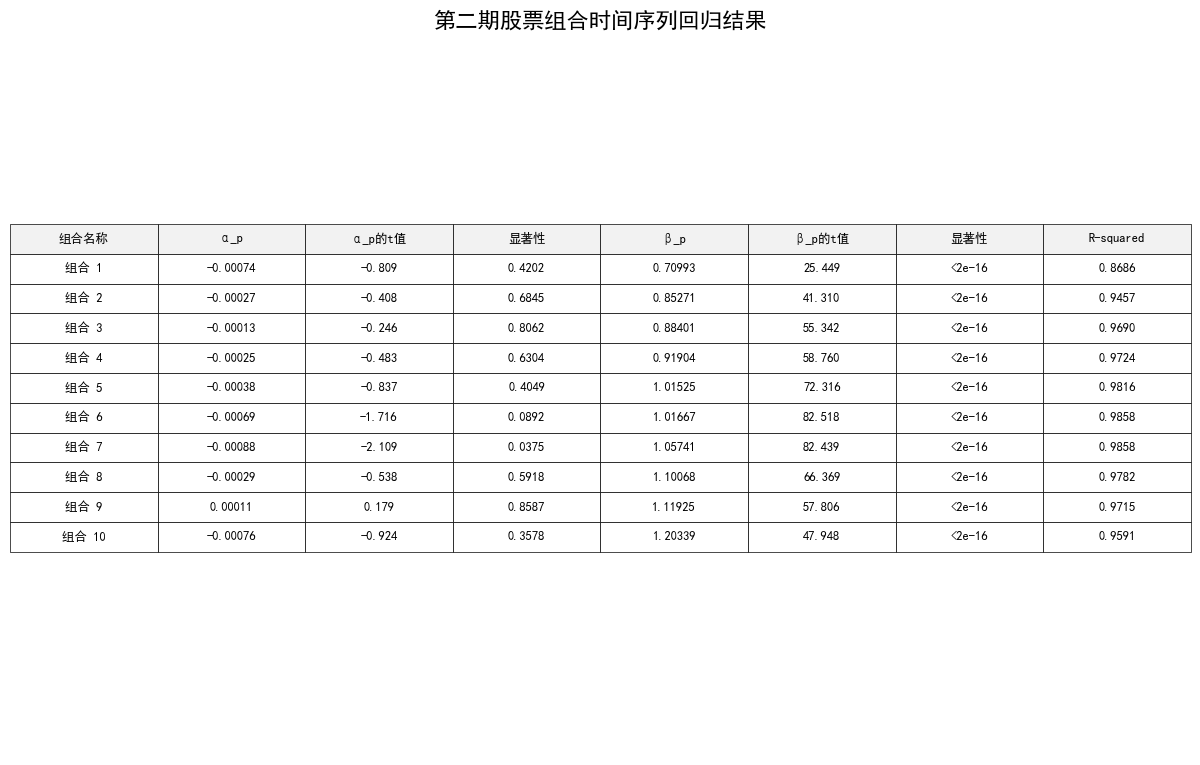

In [73]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy.stats as stats
from tabulate import tabulate
from matplotlib.font_manager import FontProperties

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'Microsoft YaHei', 'WenQuanYi Micro Hei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.family'] = 'sans-serif'

df = final_df.copy()
df = df.dropna(subset=['T1_beta', 'Wretnd', 'Market_Return', 'risk_free_return'])
time_points = sorted(df['Trdwnt'].unique())
if len(time_points) >= 200:
    selected_times = time_points[101:201]
    selected_data = df[df['Trdwnt'].isin(selected_times)].copy()
else:
    print(f"警告：数据不足200个时间点，仅有{len(time_points)}个时间点。使用所有可用数据。")
    selected_data = df.copy()

# 按照beta值分成10组
# 先处理可能存在的NaN值
selected_data_with_beta = selected_data.dropna(subset=['T1_beta'])
selected_data_with_beta ['excess_return'] = selected_data_with_beta ['Wretnd'] - selected_data_with_beta ['risk_free_return']
selected_data_with_beta ['excess_market_return'] = selected_data_with_beta ['Market_Return'] - selected_data_with_beta ['risk_free_return']

selected_data_with_beta['beta_group'] = pd.qcut(selected_data_with_beta['T1_beta'], 
                                              q=10, 
                                              labels=False) + 1


# 将分组信息以及超额收益率合并回原始DataFrame
selected_data = pd.merge(selected_data, 
                        selected_data_with_beta[['Stkcd', 'Trdwnt', 'beta_group', 'excess_return', 'excess_market_return']], 
                        on=['Stkcd', 'Trdwnt'], 
                        how='left')
# 计算每组的平均超额收益和超额市场收益
portfolio_data = selected_data_with_beta.groupby(['Trdwnt', 'beta_group']).agg({
    'excess_return': 'mean',
    'excess_market_return': 'mean'
}).reset_index()

# 存储回归结果
portfolio_betas = []
portfolio_alphas = []
portfolio_r2 = []
alpha_t_values = []
beta_t_values = []
alpha_p_values = []
beta_p_values = []
group_numbers = []

for group in range(1, 11):
    group_data = portfolio_data[portfolio_data['beta_group'] == group]
    
    if len(group_data) == 0:
        print(f"警告：组合 {group} 没有数据，跳过")
        continue
    
    group_numbers.append(group)
    
    # 准备回归数据
    X = group_data['excess_market_return'].values.reshape(-1, 1)
    y = group_data['excess_return'].values
    
    # 回归模型
    model = LinearRegression()
    model.fit(X, y)
    
    # 保存基本结果
    beta = model.coef_[0]
    alpha = model.intercept_
    r2 = model.score(X, y)
    
    portfolio_betas.append(beta)
    portfolio_alphas.append(alpha)
    portfolio_r2.append(r2)
    
    # 计算t值和p值
    n = len(X)
    k = 1  # 解释变量数量
    
    # 得到预测值
    y_pred = model.predict(X)
    
    # 计算残差
    residuals = y - y_pred
    
    # 残差平方和
    sse = np.sum(residuals**2)
    
    # 回归自由度调整后的标准误
    se = np.sqrt(sse / (n - k - 1))
    
    # X的方差
    x_mean = np.mean(X)
    x_var = np.sum((X - x_mean)**2)
    
    # 计算beta的标准误
    beta_se = se / np.sqrt(x_var)
    
    # 计算alpha的标准误
    alpha_se = se * np.sqrt(1/n + np.mean(X)**2/x_var)
    
    # 计算t值
    beta_t = beta / beta_se
    alpha_t = alpha / alpha_se
    
    # 计算p值 (双尾检验)
    beta_p = 2 * (1 - stats.t.cdf(abs(beta_t), df=n-k-1))
    alpha_p = 2 * (1 - stats.t.cdf(abs(alpha_t), df=n-k-1))
    
    # 保存t值和p值
    alpha_t_values.append(alpha_t)
    beta_t_values.append(beta_t)
    alpha_p_values.append(alpha_p)
    beta_p_values.append(beta_p)

# 创建回归结果DataFrame
results = pd.DataFrame({
    "beta_group": group_numbers,
    "组合名称": [f"组合 {i}" for i in group_numbers],
    "α_p": portfolio_alphas,
    "α_p的t值": alpha_t_values,
    "显著性": alpha_p_values,
    "β_p": portfolio_betas,
    "β_p的t值": beta_t_values,
    "β_p显著性": beta_p_values,
    "R-squared": portfolio_r2
})

# 格式化p值显示
def format_p_value(p):
    if p < 2e-16:
        return "<2e-16"
    elif p < 0.0001:
        return f"{p:.2e}"
    else:
        return f"{p:.4f}"

# 应用格式化
results["显著性"] = results["显著性"].apply(lambda x: f"{x:.4f}")
results["β_p显著性"] = results["β_p显著性"].apply(format_p_value)

# 展示表格
print("Portfolio Beta分析结果:")
print(tabulate(results, headers='keys', tablefmt='pretty', floatfmt=".5f"))

# 使用Matplotlib创建更美观的表格
fig, ax = plt.subplots(figsize=(12, 8))
ax.axis('tight')
ax.axis('off')

# 表格数据
cell_text = []
for i in range(len(results)):
    row = [results.iloc[i]["组合名称"],
           f"{results.iloc[i]['α_p']:.5f}",
           f"{results.iloc[i]['α_p的t值']:.3f}",
           results.iloc[i]['显著性'],
           f"{results.iloc[i]['β_p']:.5f}",
           f"{results.iloc[i]['β_p的t值']:.3f}",
           results.iloc[i]['β_p显著性'],
           f"{results.iloc[i]['R-squared']:.4f}"]
    cell_text.append(row)

# 创建表格
table = ax.table(
    cellText=cell_text,
    colLabels=["组合名称", "α_p", "α_p的t值", "显著性", "β_p", "β_p的t值", "显著性", "R-squared"],
    loc='center',
    cellLoc='center',
    colColours=["#f2f2f2"] * 8
)

# 设置表格样式
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.5)

# 绘制表格外边框
for key, cell in table.get_celld().items():
    cell.set_linewidth(0.5)
    
# 设置标题
plt.suptitle('第二期股票组合时间序列回归结果', fontsize=16, y=0.95)

# 调整边距
plt.tight_layout()

# 保存图片
plt.savefig('portfolio_regression_results.png', dpi=300, bbox_inches='tight')

# 显示图表
plt.show()

In [39]:
portfolio_beta_map

{1: 0.7099253828744077,
 2: 0.8527100045347046,
 3: 0.8840132414893899,
 4: 0.9190366737124392,
 5: 1.0152477553495436,
 6: 1.0166702120359181,
 7: 1.057410285661922,
 8: 1.1006833009163082,
 9: 1.1192501930782595,
 10: 1.203387697044903}

In [74]:
# 创建一个映射字典，将beta_group映射到相应的portfolio_beta
portfolio_beta_map = dict(zip(results['beta_group'], results['β_p']))

# 在selected_data中创建portfolio_beta列
selected_data['portfolio_beta'] = selected_data['beta_group'].map(portfolio_beta_map)

# 将portfolio_beta合并回final_df
# 先确保我们只从selected_data中取需要的列
portfolio_beta_data = selected_data[['Stkcd', 'Trdwnt', 'portfolio_beta','beta_group']].copy()
# Create dictionaries for mapping
beta_map = portfolio_beta_data.set_index('Stkcd')['portfolio_beta'].to_dict()
group_map = portfolio_beta_data.set_index('Stkcd')['beta_group'].to_dict()

# Apply the mappings
df = final_df.copy()
df['portfolio_beta'] = df['Stkcd'].map(beta_map)
df['beta_group'] = df['Stkcd'].map(group_map)

In [ ]:
df = df.drop(columns=['Market_Return'], inplace=False)
df.dropna(subset=['portfolio_beta'], inplace=True)
df

,Stkcd,Trdwnt,Wretnd,risk_free_return,Market_Return,T1_beta,portfolio_beta,beta_group
0,300350,2017-01,0.006833,0.000571,0.016616,1.440365,1.203388,10.0
1,001896,2017-01,0.059940,0.000571,0.016616,1.089458,1.057410,7.0
2,600246,2017-01,0.032872,0.000571,0.016616,0.609707,0.852710,2.0
3,000069,2017-01,-0.002878,0.000571,0.016616,0.663483,0.852710,2.0
4,300206,2017-01,0.009474,0.000571,0.016616,1.122307,1.057410,7.0
...,...,...,...,...,...,...,...,...
1192891,300049,2022-53,0.035608,NaN,0.013037,1.186150,1.100683,8.0
1192892,300048,2022-53,0.014614,NaN,0.013037,1.223897,1.119250,9.0
1192893,300047,2022-53,-0.009901,NaN,0.013037,1.132794,1.057410,7.0
1192894,300046,2022-53,0.012320,NaN,0.013037,1.222027,1.119250,9.0


In [63]:
len(sorted(df['Trdwnt'].unique()))

308

使用第200期之后的数据，包含104个时间点


C:\Users\sirui\AppData\Local\Temp\ipykernel_21548\3480181787.py:132: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) SimHei.
  plt.savefig('cross_sectional_regression_results.png', dpi=300, bbox_inches='tight')
C:\Users\sirui\AppData\Local\Temp\ipykernel_21548\3480181787.py:132: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) SimHei.
  plt.savefig('cross_sectional_regression_results.png', dpi=300, bbox_inches='tight')
C:\Users\sirui\AppData\Local\Temp\ipykernel_21548\3480181787.py:132: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.savefig('cross_sectional_regression_results.png', dpi=300, bbox_inches='tight')



横截面回归结果:
γ₀ = 0.0004, t值 = 0.8214, p值 = 0.4352
γ₁ = 0.0005, t值 = 1.0303, p值 = 0.3330
R² = 0.1171
F检验值 = 1.0616, p值 = 0.333000


C:\Users\sirui\AppData\Local\Temp\ipykernel_21548\3480181787.py:170: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.tight_layout()
C:\Users\sirui\AppData\Local\Temp\ipykernel_21548\3480181787.py:171: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.savefig('beta_vs_excess_return.png', dpi=300)
C:\Users\sirui\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sirui\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sirui\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


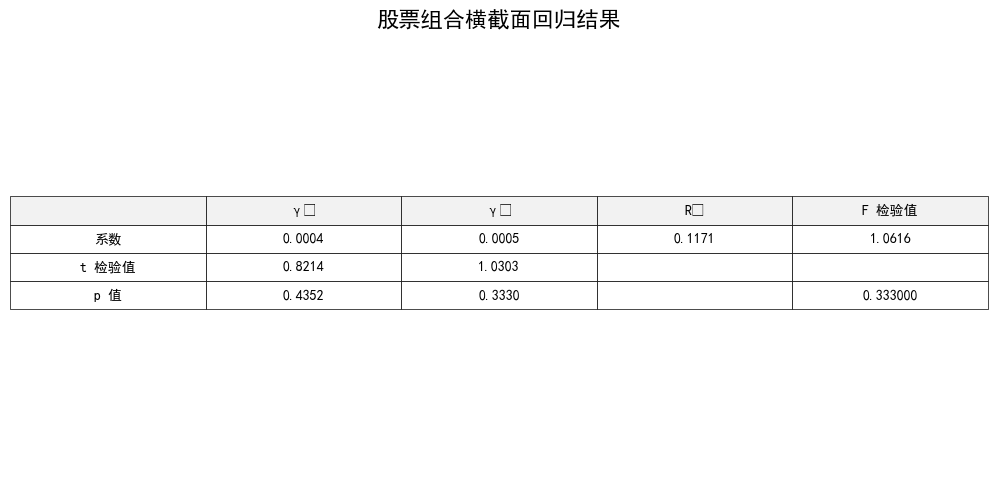

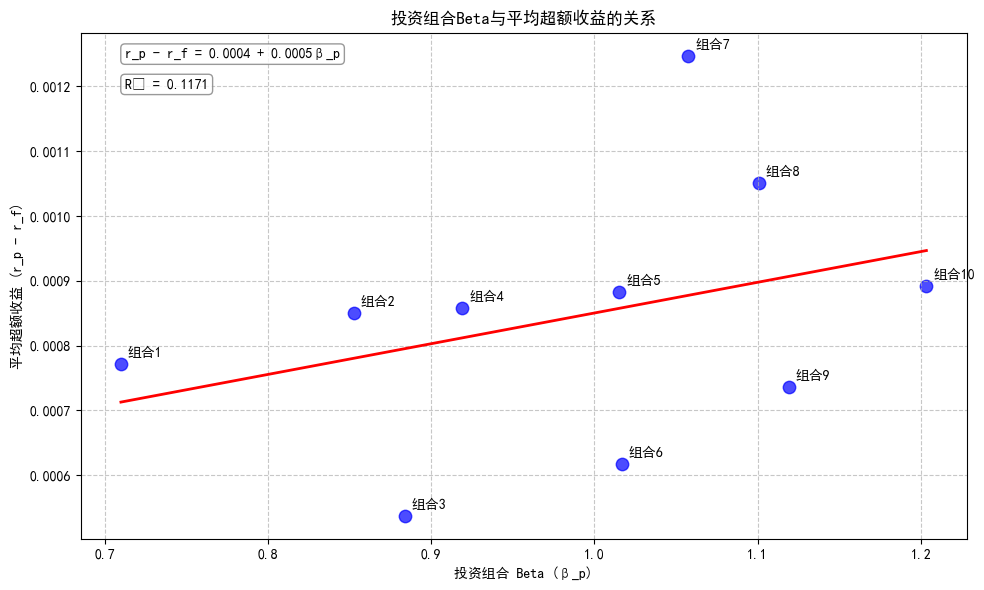

In [78]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy.stats as stats
from tabulate import tabulate
from matplotlib.font_manager import FontProperties

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'Microsoft YaHei', 'WenQuanYi Micro Hei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.family'] = 'sans-serif'
df['beta_group'] = df['beta_group'].astype(int)
# df = final_df.copy()
df = df.dropna(subset=['portfolio_beta', 'Wretnd','risk_free_return'])
time_points = sorted(df['Trdwnt'].unique())

# 取第200期之后的所有日期
if len(time_points) >= 200:
    selected_times = time_points[200:]  # 200期之后的所有日期
    selected_data = df[df['Trdwnt'].isin(selected_times)].copy()
    print(f"使用第200期之后的数据，包含{len(selected_times)}个时间点")
else:
    print(f"警告：数据不足200个时间点，仅有{len(time_points)}个时间点。使用所有可用数据。")
    selected_data = df.copy()

# 计算每个时间点每个组合的平均超额收益
# 根据portfolio_beta进行排序（剔除空值）
valid_data = selected_data.dropna(subset=['portfolio_beta','beta_group'])
# market_returns = valid_data.groupby('Trdwnt')['Wretnd'].mean().reset_index()
# market_returns = market_returns.rename(columns={'Wretnd': 'Market_Return'})

# # 将计算出的市场均值合并回原数据
# valid_data = pd.merge(valid_data, market_returns, on='Trdwnt', how='left')
valid_data['excess_return'] = valid_data['Wretnd'] - valid_data['risk_free_return']
valid_data['excess_market_return'] = valid_data['Market_Return'] - valid_data['risk_free_return']


group_returns = valid_data.groupby('beta_group')['excess_return'].mean().reset_index()

group_betas = valid_data.groupby('beta_group')['portfolio_beta'].first().reset_index()

cross_sectional_data = pd.merge(group_returns, group_betas, on='beta_group', how='inner')


# 横截面回归: r_p - r_f = γ_0 + γ_1*β_p + ε_p
X = cross_sectional_data['portfolio_beta'].values.reshape(-1, 1)
y = cross_sectional_data['excess_return'].values

model = LinearRegression()
model.fit(X, y)

# 获取回归系数
gamma_0 = model.intercept_
gamma_1 = model.coef_[0]
r2 = model.score(X, y)

# 计算标准误差和t值
n = len(X)
k = 1  # 解释变量数量
y_pred = model.predict(X)
residuals = y - y_pred
sse = np.sum(residuals**2)
se = np.sqrt(sse / (n - k - 1))

# X的方差
x_mean = np.mean(X)
x_var = np.sum((X - x_mean)**2)

# 计算beta的标准误
gamma_1_se = se / np.sqrt(x_var)

# 计算alpha的标准误
gamma_0_se = se * np.sqrt(1/n + np.mean(X)**2/x_var)

# 计算t值
gamma_0_t = gamma_0 / gamma_0_se
gamma_1_t = gamma_1 / gamma_1_se

# 计算p值 (双尾检验)
gamma_0_p = 2 * (1 - stats.t.cdf(abs(gamma_0_t), df=n-k-1))
gamma_1_p = 2 * (1 - stats.t.cdf(abs(gamma_1_t), df=n-k-1))

# 计算F统计量
f_stat = (r2 / k) / ((1 - r2) / (n - k - 1))
f_p = 1 - stats.f.cdf(f_stat, k, n - k - 1)

# 创建回归结果表格
results_table = {
    "": ["系数", "t 检验值", "p 值"],
    "γ₀": [f"{gamma_0:.4f}", f"{gamma_0_t:.4f}", f"{gamma_0_p:.4f}"],
    "γ₁": [f"{gamma_1:.4f}", f"{gamma_1_t:.4f}", f"{gamma_1_p:.4f}"],
    "R²": [f"{r2:.4f}", "", ""],
    "F 检验值": [f"{f_stat:.4f}", "", f"{f_p:.6f}"]
}

# 使用matplotlib绘制表格
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis('tight')
ax.axis('off')

# 创建表格
table = ax.table(
    cellText=[
        [results_table[""][0], results_table["γ₀"][0], results_table["γ₁"][0], results_table["R²"][0], results_table["F 检验值"][0]],
        [results_table[""][1], results_table["γ₀"][1], results_table["γ₁"][1], "", ""],
        [results_table[""][2], results_table["γ₀"][2], results_table["γ₁"][2], "", results_table["F 检验值"][2]]
    ],
    colLabels=["", "γ₀", "γ₁", "R²", "F 检验值"],
    loc='center',
    cellLoc='center',
    colColours=["#f2f2f2"] * 5
)

# 设置表格样式
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)

# 绘制表格外边框
for key, cell in table.get_celld().items():
    cell.set_linewidth(0.5)
    
# 设置标题
plt.suptitle('股票组合横截面回归结果', fontsize=16, y=0.95)

# 调整边距
plt.tight_layout()

# 保存图片
plt.savefig('cross_sectional_regression_results.png', dpi=300, bbox_inches='tight')

# 打印结果
print("\n横截面回归结果:")
print(f"γ₀ = {gamma_0:.4f}, t值 = {gamma_0_t:.4f}, p值 = {gamma_0_p:.4f}")
print(f"γ₁ = {gamma_1:.4f}, t值 = {gamma_1_t:.4f}, p值 = {gamma_1_p:.4f}")
print(f"R² = {r2:.4f}")
print(f"F检验值 = {f_stat:.4f}, p值 = {f_p:.6f}")

# 可视化结果：超额收益与portfolio_beta的关系
plt.figure(figsize=(10, 6))
plt.scatter(cross_sectional_data['portfolio_beta'], cross_sectional_data['excess_return'], 
            c='blue', alpha=0.7, s=80)

# 添加回归线
beta_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.plot(beta_range, model.predict(beta_range), 'r-', linewidth=2)

# 在图上标注回归方程
equation = f"r_p - r_f = {gamma_0:.4f} + {gamma_1:.4f}β_p"
plt.annotate(equation, xy=(0.05, 0.95), xycoords='axes fraction', 
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

# 在图上标注R²值
r2_text = f"R² = {r2:.4f}"
plt.annotate(r2_text, xy=(0.05, 0.89), xycoords='axes fraction',
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

# 标注数据点
for i, row in cross_sectional_data.iterrows():
    plt.annotate(f"组合{int(row['beta_group'])}", 
                xy=(row['portfolio_beta'], row['excess_return']),
                xytext=(5, 5), textcoords='offset points')

plt.xlabel('投资组合 Beta (β_p)')
plt.ylabel('平均超额收益 (r_p - r_f)')
plt.title('投资组合Beta与平均超额收益的关系')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('beta_vs_excess_return.png', dpi=300)
plt.show()